# 한국 인앱결제 강제금지 규제와 디지털 콘텐츠 소비 상태의 전이 — 분석 노트북

**구성**

| 부 | 내용 | 자료의 성격 |
|---|---|---|
| A | 정책 연표, 한국미디어패널 공표 집계치, 패널 유지율 | **실제 공개자료** (공표 수치를 옮겨 적은 것) |
| B | 잠재전이분석(LTA) 전 과정: 모형 선택 → 측정불변성 → 전이 동질성 검정 → 부트스트랩 → 민감도 | **모의패널** (공표 표본 크기·유지율·경험률에 맞춘 설계 보정 자료) |
| C | 설계 타당성 몬테카를로: 검정의 크기·검정력, 상태 수 선택 | **모의실험** |

> **읽기 전에.** 한국미디어패널 개인 원자료(이메일·이용 동의 필요)는 이 패키지에 들어 있지 않다.
> 따라서 B·C부의 수치는 *분석 절차가 알려진 참값을 되찾는지*를 보여 주는 검증 결과이며,
> **한국 규제의 효과 추정치로 인용할 수 없다.** 실제 원자료를 `data/private/consumer_panel.csv`
> (열: `id, wave, paid_app, inapp_item, paid_video, paid_music`)로 넣고 아래 `DATA_MODE = "real"` 로 바꾸면
> B부의 같은 코드가 실제 자료에 그대로 적용된다.

실행: 이 파일이 있는 `code/` 폴더에서 Jupyter 로 열고 **Run All**. (numpy, pandas, scipy, matplotlib, joblib 필요)

In [1]:
# ── 0. 준비 ─────────────────────────────────────────────────────────────
import json, os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

HERE = Path.cwd() if (Path.cwd() / 'lta_engine.py').exists() else Path.cwd() / 'code'
ROOT = HERE.parent
sys.path.insert(0, str(HERE))
import lta_engine as L
import study_design as D

DATA, OUT, FIG = ROOT / 'data', ROOT / 'outputs', ROOT / 'figures'
for p in (OUT, FIG):
    p.mkdir(exist_ok=True)

DATA_MODE = 'synthetic'      # 'synthetic' = 설계 보정 모의패널, 'real' = data/private/consumer_panel.csv
N_JOBS = max(1, (os.cpu_count() or 2) - 2)
N_STARTS = 10                # 모형별 무작위 초기값 수
N_BOOT = 500                 # 부트스트랩 반복 수

# 그림 공통 양식: 한글 글꼴, 흰 바탕, 옅은 격자
mpl.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110, 'savefig.dpi': 200,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a8983',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'text.color': '#0b0b0b', 'font.size': 10, 'axes.titlesize': 11, 'legend.frameon': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white'})
C = ['#2a78d6', '#eb6834', '#1baf7a']          # 상태(또는 계열) 색: 파랑·주황·청록 (고정 순서)
INK2 = '#52514e'
SYN_NOTE = '모의자료(설계 보정) · 실증 추정치 아님'


def savefig(fig, name, note=None):
    if note:
        fig.text(0.995, -0.02, note, ha='right', va='top', fontsize=7.5, color='#8a8983')
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight')
    plt.show()


print('ROOT =', ROOT, '| DATA_MODE =', DATA_MODE, '| cores used =', N_JOBS)

ROOT = (프로젝트 폴더) | DATA_MODE = synthetic | cores used = 20


## A. 실제 공개자료

### A-1. 정책·사건 연표
`data/policy_events.csv` 는 공식 문서와 보도로 확인한 날짜를 정리한 것이다(출처 URL 포함).

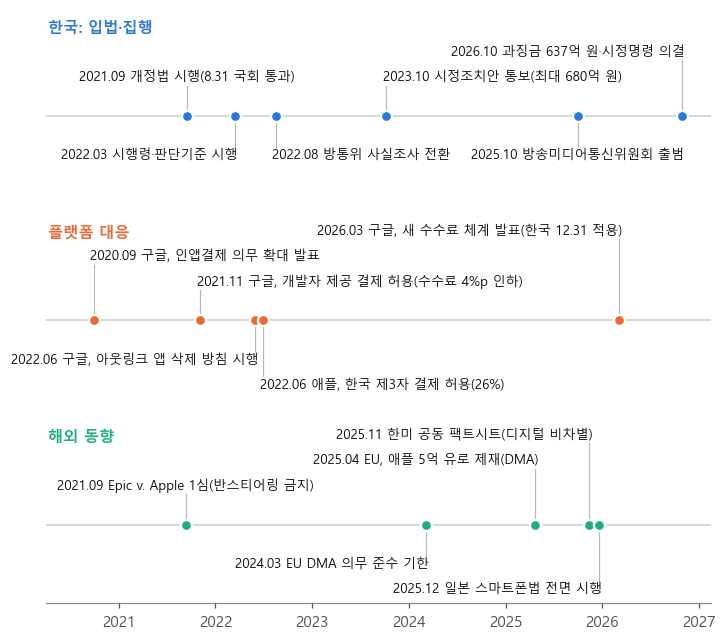

,date,lane,label,source
0,2021-09-14,한국: 입법·집행,개정법 시행(8.31 국회 통과),국회 본회의 재석 188·찬성 180·기권 8 가결 후 공포·시행
1,2022-03-15,한국: 입법·집행,시행령·판단기준 시행,"방송통신위원회 보도자료(2022-03-08), 과징금 상한 매출액 2%·1%"
2,2022-08-16,한국: 입법·집행,방통위 사실조사 전환,아이뉴스24(2022-08-09)
3,2023-10-06,한국: 입법·집행,시정조치안 통보(최대 680억 원),구글 475억·애플 205억 원(안)
4,2025-10-01,한국: 입법·집행,방송미디어통신위원회 출범,기자협회보
5,2026-10-28,한국: 입법·집행,과징금 637억 원·시정명령 의결,방송미디어통신위원회 보도자료: 구글 429억·애플 208.1억 원
6,2020-09-28,플랫폼 대응,"구글, 인앱결제 의무 확대 발표",Android Developers Blog (S. Samat)
7,2021-11-04,플랫폼 대응,"구글, 개발자 제공 결제 허용(수수료 4%p 인하)",Google 개발자 블로그
8,2022-06-01,플랫폼 대응,"구글, 아웃링크 앱 삭제 방침 시행",아이뉴스24(2022-05-31)
9,2022-06-30,플랫폼 대응,"애플, 한국 제3자 결제 허용(26%)",MacRumors


In [2]:
ev = pd.read_csv(DATA / 'policy_events.csv', parse_dates=['date'])
lanes = ['한국: 입법·집행', '플랫폼 대응', '해외 동향']
FS = 8.6                                           # 논문 폭(약 16cm)으로 줄여도 읽히는 글자 크기
GAP = 1.35                                         # 줄(lane) 사이 간격
# 이름표 자리: 날짜 → (위 1/아래 -1, 단, 글자 정렬). 글자와 연결선이 겹치지 않게 손으로 정했다.
# 사건을 추가하면 여기에 자리를 적는다(적지 않으면 위쪽 1단 가운데).
LAYOUT = {
    '2021-09-14': (1, 1, 'center'), '2022-03-15': (-1, 1, 'right'), '2022-08-16': (-1, 1, 'left'),
    '2023-10-06': (1, 1, 'left'), '2025-10-01': (-1, 1, 'center'), '2026-10-28': (1, 2, 'right'),
    '2020-09-28': (1, 2, 'left'), '2021-11-04': (1, 1, 'left'), '2022-06-01': (-1, 1, 'right'),
    '2022-06-30': (-1, 2, 'left'), '2026-03-04': (1, 3, 'right'),
    '2021-09-10': (1, 1, 'center'), '2024-03-07': (-1, 1, 'right'), '2025-04-23': (1, 2, 'right'),
    '2025-11-13': (1, 3, 'right'), '2025-12-18': (-1, 2, 'right'),
}
fig, ax = plt.subplots(figsize=(7.8, 7.0))
ax.grid(False)
for i, lane in enumerate(lanes):
    y0 = (len(lanes) - 1 - i) * GAP
    ax.axhline(y0, color='#d5d4cf', lw=1.2, zorder=1)
    ax.text(pd.Timestamp('2020-04-10'), y0 + 0.58, lane, ha='left', va='center', fontsize=10, fontweight='bold', color=C[i])
    for _, r in ev[ev['lane'] == lane].sort_values('date').iterrows():
        side, level, ha = LAYOUT.get(f"{r['date']:%Y-%m-%d}", (1, 1, 'center'))
        dy = side * (0.03 + 0.17 * level)
        nudge = pd.Timedelta(days={'center': 0, 'left': -12, 'right': 12}[ha])      # 글자 끝을 연결선에 살짝 걸친다
        ax.plot([r['date'], r['date']], [y0, y0 + dy], color='#b9b8b2', lw=0.8, zorder=2)
        ax.scatter([r['date']], [y0], s=52, color=C[i], edgecolor='white', linewidth=1.5, zorder=3)
        ax.text(r['date'] + nudge, y0 + dy + 0.012 * side, f"{r['date']:%Y.%m} {r['label']}", ha=ha,
                va='bottom' if side > 0 else 'top', fontsize=FS, color='#0b0b0b')
ax.set_ylim(-0.52, (len(lanes) - 1) * GAP + 0.70)
ax.set_xlim(pd.Timestamp('2020-04-01'), pd.Timestamp('2027-02-15'))
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.xaxis.set_major_locator(mpl.dates.YearLocator())
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y'))
savefig(fig, 'fig01_policy_timeline')
ev[['date', 'lane', 'label', 'source']].assign(date=lambda d: d['date'].dt.strftime('%Y-%m-%d'))

### A-2. 한국미디어패널 공표 집계치
아래 수치는 「2025 한국미디어패널조사」 보고서에 **공표된 가중 집계치**를 옮긴 것이다(개인 원자료 아님).
같은 개인을 추적한 값이 아니므로 상태 전이를 말해 주지 않는다. 다만 모의패널의 설계 보정 목표로 쓴다.

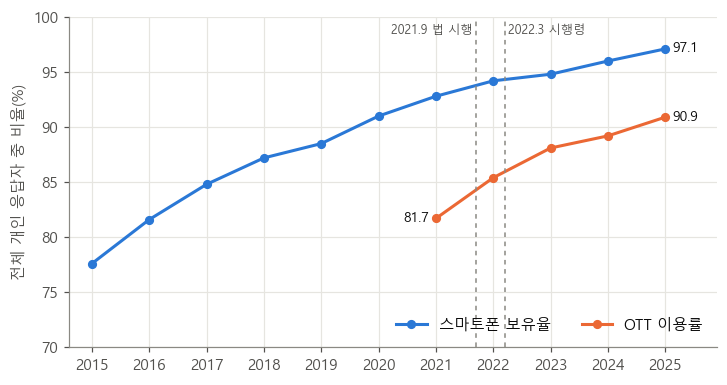

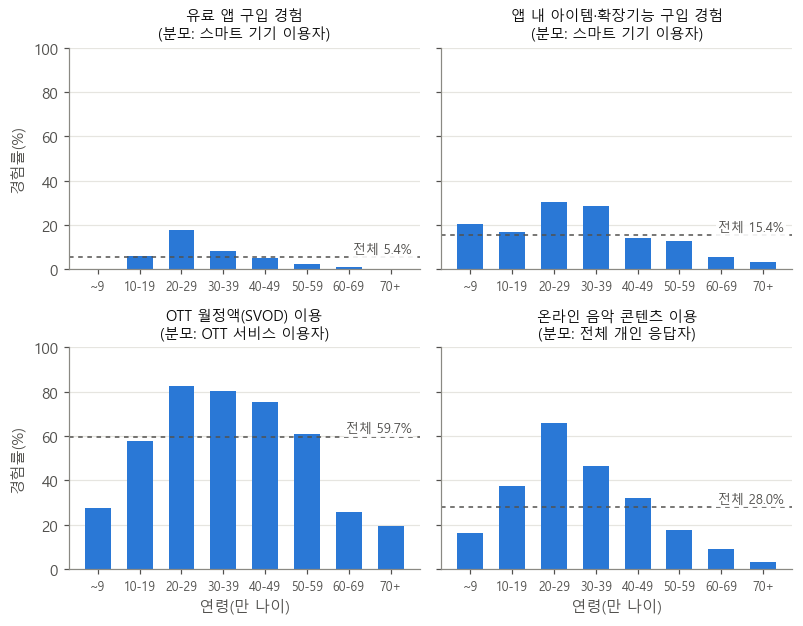

통합패널 개인 표본 유지 현황(공표값)


,year,wave_no,retained_from_prev,retention_pct,dropped,reentered,respondents
0,2019,1,10864,100.0,NaN,NaN,10864
1,2020,2,10013,92.2,851.0,289.0,10302
2,2021,3,9750,94.6,552.0,404.0,10154
3,2022,4,9593,94.5,561.0,348.0,9941
4,2023,5,9428,94.8,513.0,329.0,9757
5,2024,6,8277,84.8,1480.0,416.0,8693
6,2025,7,8002,92.1,691.0,409.0,8411


In [3]:
agg = pd.read_csv(DATA / 'kisdi_public_aggregates.csv')
ret = pd.read_csv(DATA / 'kisdi_panel_retention.csv')

# (1) 시계열: 스마트폰 보유율과 OTT 이용률(전체 개인 응답자 기준, 같은 % 축)
ts = agg[agg['group_type'] == '전체']
sp = ts[ts['indicator'] == 'smartphone_ownership']
ott = ts[ts['indicator'] == 'ott_use']
fig, ax = plt.subplots(figsize=(7.6, 3.9))
ax.plot(sp['year'], sp['value_pct'], color=C[0], lw=2, marker='o', ms=5, label='스마트폰 보유율')
ax.plot(ott['year'], ott['value_pct'], color=C[1], lw=2, marker='o', ms=5, label='OTT 이용률')
for d_, lab, ha_ in [(2021.70, '2021.9 법 시행', 'right'), (2022.20, '2022.3 시행령', 'left')]:
    ax.axvline(d_, color='#8a8983', lw=1, ls=(0, (3, 3)))
    ax.text(d_ + (0.06 if ha_ == 'left' else -0.06), 99.4, lab, fontsize=8, color=INK2, va='top', ha=ha_)
ax.text(sp['year'].iloc[-1] + 0.12, sp['value_pct'].iloc[-1], f"{sp['value_pct'].iloc[-1]:.1f}", va='center', fontsize=9)
ax.text(ott['year'].iloc[-1] + 0.12, ott['value_pct'].iloc[-1], f"{ott['value_pct'].iloc[-1]:.1f}", va='center', fontsize=9)
ax.text(ott['year'].iloc[0] - 0.12, ott['value_pct'].iloc[0], f"{ott['value_pct'].iloc[0]:.1f}", va='center', ha='right', fontsize=9)
ax.set_ylim(70, 100); ax.set_xlim(2014.6, 2025.9); ax.set_xticks(range(2015, 2026))
ax.set_ylabel('전체 개인 응답자 중 비율(%)'); ax.legend(loc='lower right', ncol=2)
savefig(fig, 'fig02_kisdi_timeseries')

# (2) 2025년 연령별 경험률: 지표마다 분모(응답 대상)가 다르므로 작은 그림 네 개로 나눈다
panels = [('paid_app', '유료 앱 구입 경험', '스마트 기기 이용자'), ('inapp_item', '앱 내 아이템·확장기능 구입 경험', '스마트 기기 이용자'),
          ('ott_svod', 'OTT 월정액(SVOD) 이용', 'OTT 서비스 이용자'), ('music_use', '온라인 음악 콘텐츠 이용', '전체 개인 응답자')]
age = agg[agg['group_type'] == '연령']
fig, axes = plt.subplots(2, 2, figsize=(7.4, 5.8), sharey=True)
for ax, (ind, title, base) in zip(axes.ravel(), panels):
    s = age[age['indicator'] == ind]
    labs = [g.replace('만 ', '').replace('세', '').replace(' 이상', '+').replace('10대 미만', '~9') for g in s['group']]
    ax.bar(labs, s['value_pct'], color=C[0], width=0.62)
    tot = agg[(agg['indicator'] == ind) & (agg['group_type'] == '전체') & (agg['year'] == 2025)]['value_pct'].iloc[0]
    ax.axhline(tot, color=INK2, lw=1, ls=(0, (3, 3)))
    ax.text(len(labs) - 0.5, tot + 2, f'전체 {tot:.1f}%', ha='right', fontsize=8.5, color=INK2,
            bbox=dict(facecolor='white', edgecolor='none', pad=1.2, alpha=0.9))
    ax.set_title(f'{title}\n(분모: {base})', fontsize=9.5)
    ax.tick_params(axis='x', labelsize=8); ax.grid(axis='x', visible=False); ax.set_ylim(0, 100)
for ax in axes[:, 0]:
    ax.set_ylabel('경험률(%)')
for ax in axes[1]:
    ax.set_xlabel('연령(만 나이)')
fig.tight_layout()
savefig(fig, 'fig03_kisdi_age_2025')

print('통합패널 개인 표본 유지 현황(공표값)')
ret[['year', 'wave_no', 'retained_from_prev', 'retention_pct', 'dropped', 'reentered', 'respondents']]

## B. 잠재전이분석(LTA)

### B-1. 분석 자료
`DATA_MODE = "synthetic"` 이면 `study_design.py` 의 설계값으로 모의패널을 만든다.

* 표본 크기 10,302명(2020년 통합패널 개인 응답자 수)과 연도별 유지율은 위 공표값을 사용.
* 상태 수 3, 상태별 응답확률·전이확률은 **가정**. 마지막 시점의 문항 평균이 2025년 공표 경험률 근처가 되도록 정함.
* 2022→2023, 2023→2024 구간에 S3→S2 전이확률을 0.06 높이는 **가상의 변화**를 심어 둠(추정 절차가 되찾는지 확인용).
* 이탈은 직전 시점에 관측된 구매 응답에 의존(MAR): 구매 경험자의 유지확률이 더 낮음.

In [4]:
ITEMS, WAVES = D.ITEMS, D.WAVES
if DATA_MODE == 'synthetic':
    rng = np.random.default_rng(D.SEED_MAIN)
    A_TRUE = D.transition_matrices(D.DELTA_MAIN)
    Y, Z, RESP = L.simulate_panel(D.N_DESIGN, D.PI0, A_TRUE, D.THETA, rng, retention=D.RETENTION,
                                  reentry=D.REENTRY, item_missing=D.ITEM_MISSING)
    # long 형식으로 저장: 조사 미참여 개체×시점은 행을 만들지 않는다(실제 원자료와 같은 모양)
    n, t = np.where(RESP)
    panel = pd.DataFrame({'id': [f'S{i + 1:05d}' for i in n], 'wave': np.array(WAVES)[t]})
    for j, it in enumerate(ITEMS):
        panel[it] = pd.array(Y[n, t, j], dtype='Float64').astype('Int64')
    panel.to_csv(DATA / 'synthetic_panel_long.csv', index=False)
    json.dump({'note': '가정한 설계값. 한국 이용자에 대한 추정치가 아님', 'N': D.N_DESIGN, 'waves': WAVES, 'items': ITEMS,
               'pi0': D.PI0.tolist(), 'theta': D.THETA.tolist(), 'A': A_TRUE.tolist(), 'delta': D.DELTA_MAIN,
               'retention': D.RETENTION.tolist(), 'reentry': D.REENTRY, 'item_missing': D.ITEM_MISSING,
               'seed': D.SEED_MAIN}, open(DATA / 'dgp_true_parameters.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
    DATA_LABEL, NOTE = '모의패널', SYN_NOTE
else:
    panel = pd.read_csv(DATA / 'private' / 'consumer_panel.csv', dtype={'id': str})
    assert not panel.duplicated(['id', 'wave']).any(), '같은 개인·연도 중복 행이 있습니다'
    assert panel[ITEMS].stack().isin([0, 1]).all(), '지표는 0/1/결측만 허용합니다'
    A_TRUE, DATA_LABEL, NOTE = None, '실제 패널', None

Y, IDS = L.panel_to_array(panel, 'id', 'wave', ITEMS, WAVES)
N, T, J = Y.shape
obs_wave = (~np.isnan(Y)).any(2)

flow = pd.DataFrame({'wave': WAVES, '응답자 수': obs_wave.sum(0), '응답률(%)': 100 * obs_wave.mean(0)})
flow['직전 시점 응답자 중 유지(%)'] = [np.nan] + [100 * (obs_wave[:, t] & obs_wave[:, t - 1]).sum() / obs_wave[:, t - 1].sum() for t in range(1, T)]
prev = pd.DataFrame(np.nanmean(Y, axis=0) * 100, index=WAVES, columns=ITEMS).round(2)
miss = pd.DataFrame(100 * np.isnan(Y[obs_wave.any(1)]).mean(0), index=WAVES, columns=ITEMS).round(2)
n_wave = pd.Series(obs_wave.sum(1)).value_counts().sort_index()
flow.round(2).to_csv(OUT / 'sample_flow.csv', index=False)
prev.to_csv(OUT / 'observed_prevalence_by_wave.csv')
print(f'{DATA_LABEL}: 개체 {N:,}명 × 시점 {T}개 × 문항 {J}개, 개체×시점 관측 {obs_wave.sum():,}건')
print('응답 시점 수 분포:', n_wave.to_dict(), '| 5개 시점 모두 응답:', int((obs_wave.sum(1) == T).sum()))
display(flow.round(2)); print('시점별 관측 경험률(%)'); display(prev)

if DATA_MODE == 'synthetic':
    calib = pd.DataFrame({'모의패널 2024년 관측 경험률(%)': prev.loc[2024]}).reindex(ITEMS)
    calib['2025년 공표 수치(%)'] = [5.4, 15.4, 54.3, 28.0]
    calib['공표 수치의 기준'] = ['스마트 기기 이용자 중 구입 경험률', '스마트 기기 이용자 중 구입 경험률',
                           'OTT 이용자 중 월정액 이용 59.7% × 전체 OTT 이용률 90.9%', '전체 응답자 중 온라인 음악 이용률(무료 이용 포함, 상한)']
    calib.to_csv(OUT / 'calibration_check.csv'); display(calib)

모의패널: 개체 10,302명 × 시점 5개 × 문항 4개, 개체×시점 관측 46,643건
응답 시점 수 분포: {1: 208, 2: 372, 3: 578, 4: 1763, 5: 7381} | 5개 시점 모두 응답: 7381


,wave,응답자 수,응답률(%),직전 시점 응답자 중 유지(%)
0,2020,10302,100.00,NaN
1,2021,9740,94.54,94.54
2,2022,9368,90.93,94.52
3,2023,9156,88.88,94.95
4,2024,8077,78.40,84.39


시점별 관측 경험률(%)


,paid_app,inapp_item,paid_video,paid_music
2020,4.79,11.92,43.68,22.02
2021,4.90,13.12,48.03,24.66
2022,5.61,14.41,49.91,25.55
2023,5.84,14.75,51.88,27.21
2024,6.59,15.00,54.21,28.31


,모의패널 2024년 관측 경험률(%),2025년 공표 수치(%),공표 수치의 기준
paid_app,6.59,5.4,스마트 기기 이용자 중 구입 경험률
inapp_item,15.00,15.4,스마트 기기 이용자 중 구입 경험률
paid_video,54.21,54.3,OTT 이용자 중 월정액 이용 59.7% × 전체 OTT 이용률 90.9%
paid_music,28.31,28.0,"전체 응답자 중 온라인 음악 이용률(무료 이용 포함, 상한)"


### B-2. 상태 수 선택
K = 1~5 를 각각 무작위 초기값 10개로 적합한다. 응답확률은 시점 간 동일(측정불변), 전이행렬은 구간마다 자유.
수렴한 해 중 로그우도가 가장 큰 것을 택하고, 그 값이 다른 초기값에서 재현된 횟수를 함께 본다.

BIC 최소: K = 3  (소요 133초, 서로 다른 응답 궤적 5,161개)


,K,loglik,npar,AIC,BIC,converged_starts,n_starts,best_replicated,smallest_state_share,mean_max_posterior,entropy,dBIC
0,1,-86460.492,4,172928.984,172957.944,1,1,1,1.000,1.000,1.000,31798.724
1,2,-72184.479,17,144402.958,144526.040,10,10,10,0.402,0.943,0.791,3366.820
2,3,-70404.048,38,140884.096,141159.220,10,10,10,0.114,0.890,0.745,0.000
3,4,-70380.616,67,140895.233,141380.319,3,10,1,0.052,0.860,0.743,221.099
4,5,-70370.959,104,140949.918,141702.887,1,10,1,0.019,0.793,0.652,543.667


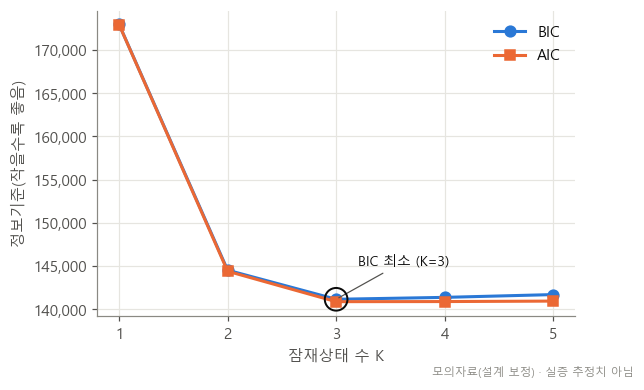

In [5]:
t0 = time.time()
fits = {}
for K in range(1, 6):
    fits[K] = L.fit(Y, K, n_starts=1 if K == 1 else N_STARTS, seed=1104, n_jobs=N_JOBS)
sel = pd.DataFrame([dict(K=K, loglik=f['loglik'], npar=f['npar'], AIC=f['aic'], BIC=f['bic'],
                         converged_starts=sum(s['converged'] for s in f['starts']), n_starts=len(f['starts']),
                         best_replicated=f['n_replicated'],
                         smallest_state_share=float(L.state_occupancy(f['pi'], f['A']).min()),
                         mean_max_posterior=L.classification_quality(Y, f['gamma'])[0],
                         entropy=L.classification_quality(Y, f['gamma'])[1]) for K, f in fits.items()])
sel['dBIC'] = sel['BIC'] - sel['BIC'].min()
K_SEL = int(sel.loc[sel['BIC'].idxmin(), 'K'])
sel.to_csv(OUT / 'model_selection.csv', index=False)
print(f'BIC 최소: K = {K_SEL}  (소요 {time.time() - t0:.0f}초, 서로 다른 응답 궤적 {fits[K_SEL]["n_patterns"]:,}개)')
display(sel.round(3))

fig, ax = plt.subplots(figsize=(5.6, 3.6))
ax.plot(sel['K'], sel['BIC'], color=C[0], lw=2, marker='o', ms=7, label='BIC')
ax.plot(sel['K'], sel['AIC'], color=C[1], lw=2, marker='s', ms=6, label='AIC')
ax.scatter([K_SEL], [sel['BIC'].min()], s=220, facecolor='none', edgecolor='#0b0b0b', lw=1.3, zorder=5)
ax.annotate(f'BIC 최소 (K={K_SEL})', (K_SEL, sel['BIC'].min()), xytext=(14, 22), textcoords='offset points', fontsize=9,
            arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
ax.set_xticks(sel['K']); ax.set_xlabel('잠재상태 수 K'); ax.set_ylabel('정보기준(작을수록 좋음)')
ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter('{x:,.0f}')); ax.legend()
savefig(fig, 'fig04_model_selection', NOTE)

### B-3. 측정불변성과 전이 동질성
* **측정불변성**: 선택한 K 에서 응답확률을 시점별로 자유화한 모형과 BIC 를 비교.
* **전이 동질성**: (a) 모든 구간 같은 전이행렬 → (b) 두 국면(2020–22 / 2022–24) → (c) 구간별 자유.
  포함관계이므로 우도비 검정을 쓴다. *전이확률이 시기에 따라 달라졌는지*를 보는 것이며 그 원인(정책 효과)을 식별하지는 않는다.

In [6]:
best = fits[K_SEL]
warm = (best['pi'], best['A'], best['theta'])
REGIMES = [0, 0, 1, 1]       # 0 = 2020→21, 21→22 / 1 = 22→23, 23→24
free = L.fit(Y, K_SEL, n_starts=N_STARTS, invariant=False, init=warm, seed=2204, n_jobs=N_JOBS)
hom = L.fit(Y, K_SEL, n_starts=N_STARTS, homog=True, init=warm, seed=3304, n_jobs=N_JOBS)
reg = L.fit(Y, K_SEL, n_starts=N_STARTS, a_groups=REGIMES, init=warm, seed=4404, n_jobs=N_JOBS)

inv = pd.DataFrame([dict(model='응답확률 시점 간 동일(불변)', loglik=best['loglik'], npar=best['npar'], BIC=best['bic'], AIC=best['aic']),
                    dict(model='응답확률 시점별 자유', loglik=free['loglik'], npar=free['npar'], BIC=free['bic'], AIC=free['aic'])])
inv['dBIC_vs_invariant'] = inv['BIC'] - best['bic']
inv.to_csv(OUT / 'measurement_invariance.csv', index=False); display(inv.round(3))

tests = []
for name, r, f in [('동질 vs 구간별 자유(총괄)', hom, best), ('동질 vs 두 국면(초점)', hom, reg), ('두 국면 vs 구간별 자유', reg, best)]:
    lr = L.lr_test(r, f)
    tests.append(dict(test=name, LR=lr['stat'], df=lr['df'], p=lr['p'], BIC_restricted=r['bic'], BIC_full=f['bic']))
tests = pd.DataFrame(tests); tests.to_csv(OUT / 'transition_homogeneity_tests.csv', index=False)
display(tests.round(4))

,model,loglik,npar,BIC,AIC,dBIC_vs_invariant
0,응답확률 시점 간 동일(불변),-70404.048,38,141159.220,140884.096,0.000
1,응답확률 시점별 자유,-70384.813,86,141564.273,140941.625,405.053


,test,LR,df,p,BIC_restricted,BIC_full
0,동질 vs 구간별 자유(총괄),27.0133,18,0.0787,141019.9116,141159.2199
1,동질 vs 두 국면(초점),11.0798,6,0.0859,141019.9116,141064.2723
2,두 국면 vs 구간별 자유,15.9335,12,0.1943,141064.2723,141159.2199


### B-4. 부트스트랩 구간추정
개인의 **전체 궤적**을 재표집한다(다항 가중치). 반복마다 선택한 모형을 최우추정값에서 출발해 다시 적합하고,
상태 번호는 응답 프로파일로 정렬한다. 선택한 K 를 고정한 구간이므로 모형 선택의 불확실성은 들어 있지 않다.
군집(가구)·층화 정보가 없는 모의패널이므로 개인 단위 재표집이다.

In [7]:
def boot_one(b):
    r = np.random.default_rng([20261106, b])
    w = r.multinomial(N, np.full(N, 1.0 / N)).astype(float)
    f = L.fit(Y, K_SEL, n_starts=1, init=warm, w=w, tol=1e-8, maxit=2000)
    return dict(pi=f['pi'], A=f['A'], theta=f['theta'][0], occ=L.state_occupancy(f['pi'], f['A']), ok=f['converged'])

t0 = time.time()
boots = Parallel(n_jobs=N_JOBS)(delayed(boot_one)(b) for b in range(N_BOOT))
valid = [b for b in boots if b['ok']]
print(f'부트스트랩 {N_BOOT}회 중 수렴 {len(valid)}회 ({time.time() - t0:.0f}초)')
ci = lambda key: np.percentile(np.array([b[key] for b in valid]), [2.5, 97.5], axis=0)
CI_TH, CI_A, CI_OCC, CI_PI = ci('theta'), ci('A'), ci('occ'), ci('pi')
OCC = L.state_occupancy(best['pi'], best['A'])
SL = D.STATE_LABELS if K_SEL == 3 else [f'S{k + 1}' for k in range(K_SEL)]

prof = pd.DataFrame([dict(item=ITEMS[j], state=SL[k], estimate=best['theta'][0, j, k], ci_low=CI_TH[0, j, k], ci_high=CI_TH[1, j, k])
                     for j in range(J) for k in range(K_SEL)])
trans = pd.DataFrame([dict(interval=f'{WAVES[t]}→{WAVES[t + 1]}', from_state=SL[a], to_state=SL[b], estimate=best['A'][t, a, b],
                           ci_low=CI_A[0, t, a, b], ci_high=CI_A[1, t, a, b])
                      for t in range(T - 1) for a in range(K_SEL) for b in range(K_SEL)])
occ = pd.DataFrame([dict(wave=WAVES[t], state=SL[k], estimate=OCC[t, k], ci_low=CI_OCC[0, t, k], ci_high=CI_OCC[1, t, k])
                    for t in range(T) for k in range(K_SEL)])
if A_TRUE is not None and K_SEL == 3:
    prof['true'] = [D.THETA[j, k] for j in range(J) for k in range(3)]
    trans['true'] = [A_TRUE[t, a, b] for t in range(T - 1) for a in range(3) for b in range(3)]
    occ['true'] = L.state_occupancy(D.PI0, A_TRUE).ravel()
    for d_ in (prof, trans, occ):
        d_['covered'] = (d_['ci_low'] <= d_['true']) & (d_['true'] <= d_['ci_high'])
    print('95% 구간이 참값을 포함한 비율 — 응답확률 {}/{}, 전이확률 {}/{}, 상태 비중 {}/{}'.format(
        prof['covered'].sum(), len(prof), trans['covered'].sum(), len(trans), occ['covered'].sum(), len(occ)))
    print('최대 절대오차 — 응답확률 {:.4f}, 전이확률 {:.4f}'.format((prof['estimate'] - prof['true']).abs().max(), (trans['estimate'] - trans['true']).abs().max()))
prof.to_csv(OUT / 'response_profiles.csv', index=False); trans.to_csv(OUT / 'transition_probabilities.csv', index=False)
occ.to_csv(OUT / 'state_occupancy.csv', index=False)
display(prof.round(4))

부트스트랩 500회 중 수렴 500회 (38초)
95% 구간이 참값을 포함한 비율 — 응답확률 12/12, 전이확률 34/36, 상태 비중 14/15
최대 절대오차 — 응답확률 0.0059, 전이확률 0.0433


,item,state,estimate,ci_low,ci_high,true,covered
0,paid_app,S1 저소비,0.0052,0.0041,0.0064,0.005,True
1,paid_app,S2 구독 중심,0.0293,0.0254,0.0332,0.030,True
2,paid_app,S3 복합 구매,0.3007,0.2858,0.3150,0.300,True
3,inapp_item,S1 저소비,0.0197,0.0176,0.0219,0.020,True
4,inapp_item,S2 구독 중심,0.1016,0.0939,0.1093,0.100,True
5,inapp_item,S3 복합 구매,0.6524,0.6313,0.6727,0.650,True
6,paid_video,S1 저소비,0.1043,0.0981,0.1098,0.100,True
7,paid_video,S2 구독 중심,0.8441,0.8347,0.8526,0.850,True
8,paid_video,S3 복합 구매,0.9047,0.8956,0.9131,0.900,True
9,paid_music,S1 저소비,0.0301,0.0269,0.0327,0.030,True


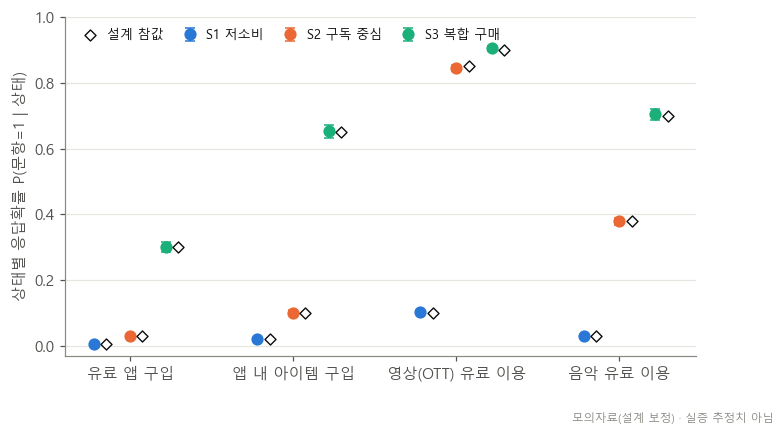

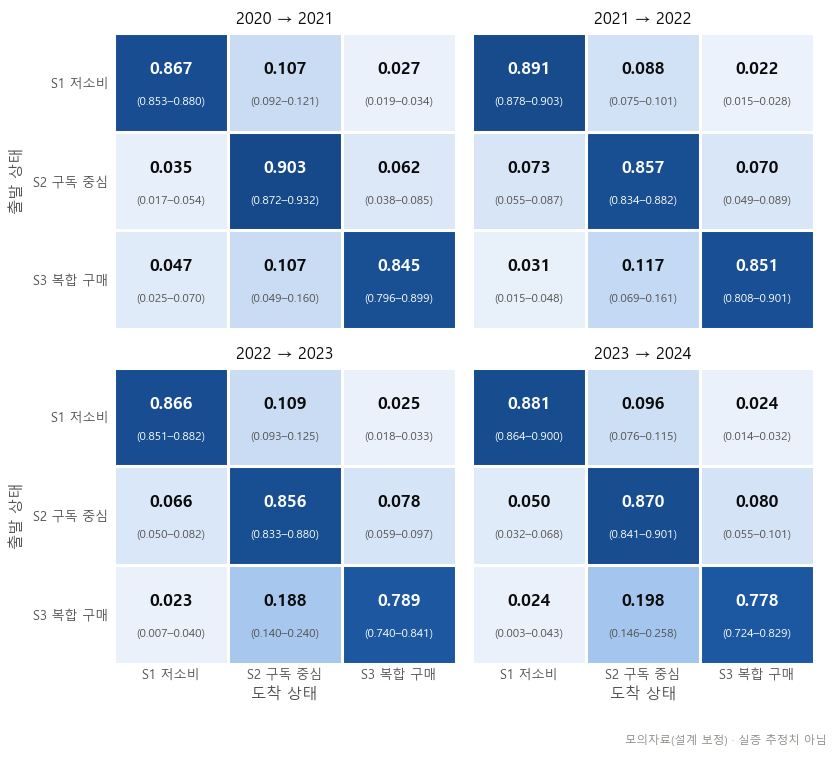

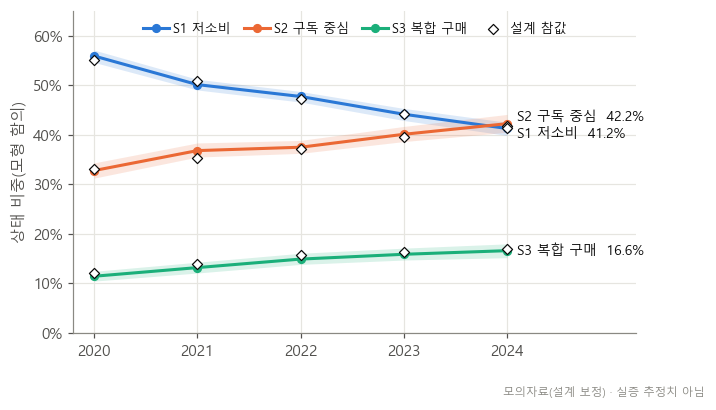

In [8]:
# 그림: 상태별 응답 프로파일(점 = 추정값, 막대 = 95% 부트스트랩 구간, 빈 마름모 = 설계 참값)
fig, ax = plt.subplots(figsize=(7.4, 4.0))
off = np.linspace(-0.22, 0.22, K_SEL)
for k in range(K_SEL):
    x = np.arange(J) + off[k]
    est = best['theta'][0, :, k]
    ax.errorbar(x, est, yerr=[est - CI_TH[0, :, k], CI_TH[1, :, k] - est], fmt='o', color=C[k % 3], ms=7, lw=1.6, capsize=3, label=SL[k])
    if A_TRUE is not None and K_SEL == 3:
        ax.scatter(x + 0.075, D.THETA[:, k], marker='D', s=26, facecolor='white', edgecolor='#0b0b0b', lw=0.9, zorder=4,
                   label='설계 참값' if k == K_SEL - 1 else None)
ax.set_xticks(range(J)); ax.set_xticklabels([D.ITEM_LABELS[i] for i in ITEMS])
ax.set_ylim(-0.03, 1.0); ax.set_ylabel('상태별 응답확률 P(문항=1 | 상태)'); ax.grid(axis='x', visible=False)
ax.legend(ncol=4, loc='upper left', fontsize=8.5, handletextpad=0.3, columnspacing=1.0)
savefig(fig, 'fig05_response_profiles', NOTE)

# 그림: 구간별 전이확률(단일 색상 농담). 칸 = 추정값, 괄호 = 95% 구간
ncol = 2
nrow = int(np.ceil((T - 1) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(7.6, 3.3 * nrow), sharex=True, sharey=True)
cmap = mpl.colors.LinearSegmentedColormap.from_list('blue', ['#f4f8fd', '#2a78d6', '#123f78'])
for t, ax in enumerate(np.atleast_1d(axes).ravel()):
    if t >= T - 1:
        ax.axis('off'); continue
    ax.imshow(best['A'][t], cmap=cmap, vmin=0, vmax=1, aspect='auto'); ax.grid(False)
    for a in range(K_SEL):
        for b in range(K_SEL):
            v = best['A'][t, a, b]
            ax.text(b, a - 0.13, f'{v:.3f}', ha='center', va='center', fontsize=11, color='white' if v > 0.55 else '#0b0b0b', fontweight='bold')
            ax.text(b, a + 0.2, f'({CI_A[0, t, a, b]:.3f}–{CI_A[1, t, a, b]:.3f})', ha='center', va='center', fontsize=7.6,
                    color='white' if v > 0.55 else INK2)
    ax.set_xticks(range(K_SEL)); ax.set_xticklabels(SL, fontsize=8.5); ax.set_yticks(range(K_SEL)); ax.set_yticklabels(SL, fontsize=8.5)
    ax.set_title(f'{WAVES[t]} → {WAVES[t + 1]}', fontsize=10.5)
    for s_ in ax.spines.values(): s_.set_visible(False)
    ax.set_xticks(np.arange(-.5, K_SEL), minor=True); ax.set_yticks(np.arange(-.5, K_SEL), minor=True)
    ax.grid(which='minor', color='white', lw=2); ax.tick_params(which='both', length=0)
    ax.set_xlim(-0.5, K_SEL - 0.5); ax.set_ylim(K_SEL - 0.5, -0.5)
    if t % ncol == 0: ax.set_ylabel('출발 상태')
    if t >= (nrow - 1) * ncol: ax.set_xlabel('도착 상태')
fig.tight_layout()
savefig(fig, 'fig06_transition_matrices', NOTE)

# 그림: 시점별 상태 비중
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ylab = OCC[-1].copy()                               # 끝점 이름표가 겹치지 않게 최소 간격을 둔다
order = np.argsort(ylab)
for a_, b_ in zip(order[:-1], order[1:]):
    if ylab[b_] - ylab[a_] < 0.035:
        mid = (ylab[a_] + ylab[b_]) / 2; ylab[a_], ylab[b_] = mid - 0.0175, mid + 0.0175
for k in range(K_SEL):
    ax.fill_between(WAVES, CI_OCC[0, :, k], CI_OCC[1, :, k], color=C[k % 3], alpha=0.16, lw=0)
    ax.plot(WAVES, OCC[:, k], color=C[k % 3], lw=2, marker='o', ms=5, label=SL[k])
    ax.text(WAVES[-1] + 0.1, ylab[k], f'{SL[k]}  {OCC[-1, k]:.1%}', va='center', fontsize=9)
    if A_TRUE is not None and K_SEL == 3:
        ax.scatter(WAVES, L.state_occupancy(D.PI0, A_TRUE)[:, k], marker='D', s=22, facecolor='white', edgecolor='#0b0b0b', lw=0.8, zorder=4,
                   label='설계 참값' if k == K_SEL - 1 else None)
ax.set_xticks(WAVES); ax.set_xlim(WAVES[0] - 0.2, WAVES[-1] + 1.25); ax.set_ylim(0, 0.65)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_ylabel('상태 비중(모형 함의)')
ax.legend(loc='upper center', ncol=4, fontsize=8.5, handletextpad=0.3, columnspacing=1.0)
savefig(fig, 'fig07_state_occupancy', NOTE)

### B-5. 분류 불확실성과 조건부 독립 진단
* 평균 최대 사후확률·정규화 엔트로피: 개체×시점을 한 상태로 확정 분류할 때의 불확실성.
* 문항쌍 잔차(BVR): 관측 2×2 빈도와 모형 기대빈도의 Pearson 불일치. 값이 크면 그 문항쌍에 상태로 설명되지 않는 연관이 남아 있다는 신호다(p-value 아님).

In [9]:
mmp, ent = L.classification_quality(Y, best['gamma'])
bvr = pd.DataFrame(L.bivariate_residuals(Y, best))
bvr['wave'] = [WAVES[t] for t in bvr['wave_index']]
bvr['pair'] = [f'{ITEMS[a]} × {ITEMS[b]}' for a, b in zip(bvr['item_a'], bvr['item_b'])]
bvr_tab = bvr.pivot(index='pair', columns='wave', values='bvr').round(2)
bvr_tab['최대'] = bvr_tab.max(1)
bvr_tab.to_csv(OUT / 'bivariate_residuals.csv')
diag = dict(mean_max_posterior=mmp, normalized_entropy=ent, max_bvr=float(bvr['bvr'].max()),
            share_max_posterior_below_0_7=float((best['gamma'][obs_wave].max(1) < 0.7).mean()))
json.dump(diag, open(OUT / 'classification_diagnostics.json', 'w'), indent=1)
print(diag); display(bvr_tab)

{'mean_max_posterior': 0.8902524969355332, 'normalized_entropy': 0.7448462349735044, 'max_bvr': 6.746026328879565, 'share_max_posterior_below_0_7': 0.12895825740196815}


wave,2020,2021,2022,2023,2024,최대
pair,,,,,,
inapp_item × paid_music,0.07,0.57,3.87,1.78,6.75,6.75
inapp_item × paid_video,0.21,1.96,0.24,4.19,6.38,6.38
paid_app × inapp_item,0.74,4.73,0.96,3.04,6.10,6.10
paid_app × paid_music,0.76,3.20,3.10,1.83,1.77,3.20
paid_app × paid_video,1.59,2.62,2.60,4.48,1.75,4.48
paid_video × paid_music,0.04,0.56,2.75,2.16,1.99,2.75


### B-6. 민감도 분석
1. **완전응답자만**(5개 시점 모두 응답): 이탈이 구매 경험과 관련되면 상태 비중이 달라진다.
2. **2021년 제외**: 2021년 조사의 회상기간이 법 시행 전후에 걸칠 수 있으므로 빼고 적합(2020→2022 는 2년 간격).
3. **이웃 상태 수**(K−1, K+1)의 결과는 B-2 표를 참고.

In [10]:
cc = obs_wave.all(1)
fit_cc = L.fit(Y[cc], K_SEL, n_starts=N_STARTS, init=warm, seed=5504, n_jobs=N_JOBS)
keep = [i for i, w_ in enumerate(WAVES) if w_ != 2021]
fit_no21 = L.fit(Y[:, keep], K_SEL, n_starts=N_STARTS, seed=6604, n_jobs=N_JOBS)

def summarize(name, f, n_used, waves):
    o = L.state_occupancy(f['pi'], f['A'])
    d = dict(spec=name, n_persons=int(n_used), loglik=f['loglik'])
    for k in range(K_SEL):
        d[f'{SL[k]} 첫 시점 비중'] = o[0, k]; d[f'{SL[k]} 마지막 시점 비중'] = o[-1, k]
    for j in range(J):
        d[f'{ITEMS[j]} | {SL[-1]}'] = f['theta'][0, j, -1]
    d[f'{SL[-1]}→{SL[1]} 마지막 구간'] = f['A'][-1, -1, 1]
    return d

sens = pd.DataFrame([summarize('주 분석(전체, 결측 주변화)', best, N, WAVES),
                     summarize('완전응답자만', fit_cc, cc.sum(), WAVES),
                     summarize('2021년 제외(4개 시점)', fit_no21, N, [w_ for w_ in WAVES if w_ != 2021])])
if A_TRUE is not None and K_SEL == 3:
    o = L.state_occupancy(D.PI0, A_TRUE)
    tr = dict(spec='설계 참값', n_persons=np.nan, loglik=np.nan)
    for k in range(3):
        tr[f'{SL[k]} 첫 시점 비중'] = o[0, k]; tr[f'{SL[k]} 마지막 시점 비중'] = o[-1, k]
    for j in range(J):
        tr[f'{ITEMS[j]} | {SL[-1]}'] = D.THETA[j, -1]
    tr[f'{SL[-1]}→{SL[1]} 마지막 구간'] = A_TRUE[-1, -1, 1]
    sens = pd.concat([sens, pd.DataFrame([tr])], ignore_index=True)
sens.to_csv(OUT / 'sensitivity.csv', index=False)
sens.set_index('spec').T.round(4)

spec,"주 분석(전체, 결측 주변화)",완전응답자만,2021년 제외(4개 시점),설계 참값
n_persons,10302.0000,7381.0000,10302.0000,NaN
loglik,-70404.0482,-54611.2474,-57273.8821,NaN
S1 저소비 첫 시점 비중,0.5587,0.5749,0.5588,0.5500
S1 저소비 마지막 시점 비중,0.4124,0.4272,0.4119,0.4177
S2 구독 중심 첫 시점 비중,0.3273,0.3261,0.3267,0.3300
S2 구독 중심 마지막 시점 비중,0.4220,0.4176,0.4238,0.4130
S3 복합 구매 첫 시점 비중,0.1139,0.0990,0.1145,0.1200
S3 복합 구매 마지막 시점 비중,0.1656,0.1552,0.1643,0.1693
paid_app | S3 복합 구매,0.3007,0.3015,0.3049,0.3000
inapp_item | S3 복합 구매,0.6524,0.6576,0.6548,0.6500


## C. 설계 타당성 몬테카를로
`03_monte_carlo.py` 의 결과를 읽는다(파일이 없으면 여기서 실행 — 수 분~수십 분 소요).

* **실험 A**: N ∈ {500, 2000, 8000} × Δ ∈ {0, 0.03, 0.06, 0.10}, 조건당 200회.
  Δ = 2022→2023 이후 S3→S2 전이확률의 증가폭. 유의수준 5%의 우도비 검정 기각률.
* **실험 B**: N 별 100회, BIC 가 K=3 을 고른 비율.

,N,delta,reps,reject_rate,reject_mcse,reject_rate_regime,reject_mcse_regime,shift_regime_mean,shift_regime_rmse,shift_mean,shift_bias,shift_sd,shift_rmse,mae_A,mae_theta,pct_converged
0,500,0.00,200,0.050,0.0154,0.080,0.0192,0.0037,0.1003,0.0019,0.0019,0.0934,0.0932,0.0441,0.0158,100.0
1,500,0.03,200,0.035,0.0130,0.105,0.0217,0.0229,0.1130,0.0195,-0.0105,0.1021,0.1023,0.0439,0.0161,100.0
2,500,0.06,200,0.055,0.0161,0.065,0.0174,0.0378,0.1197,0.0348,-0.0252,0.1109,0.1134,0.0450,0.0158,100.0
3,500,0.10,200,0.035,0.0130,0.060,0.0168,0.1062,0.1111,0.0946,-0.0054,0.1014,0.1013,0.0449,0.0171,100.0
4,2000,0.00,200,0.035,0.0130,0.060,0.0168,0.0013,0.0571,0.0017,0.0017,0.0566,0.0565,0.0229,0.0076,100.0
5,2000,0.03,200,0.070,0.0180,0.050,0.0154,0.0280,0.0517,0.0276,-0.0024,0.0519,0.0518,0.0227,0.0079,100.0
6,2000,0.06,200,0.095,0.0207,0.115,0.0226,0.0556,0.0562,0.0548,-0.0052,0.0555,0.0556,0.0232,0.0083,100.0
7,2000,0.10,200,0.170,0.0266,0.245,0.0304,0.1003,0.0576,0.0984,-0.0016,0.0576,0.0574,0.0230,0.0084,100.0
8,8000,0.00,200,0.050,0.0154,0.050,0.0154,-0.0001,0.0266,-0.0002,-0.0002,0.0269,0.0269,0.0113,0.0038,100.0
9,8000,0.03,200,0.115,0.0226,0.130,0.0238,0.0308,0.0272,0.0312,0.0012,0.0275,0.0275,0.0115,0.0039,100.0


,N,reps,pct_bic_k2,pct_bic_k3,pct_bic_k4,mean_dbic_3_vs_2,mean_dbic_3_vs_4
0,500,100,0.0,100.0,0.0,67.75,146.43
1,2000,100,0.0,100.0,0.0,561.70,187.07
2,8000,100,0.0,100.0,0.0,2628.89,238.57


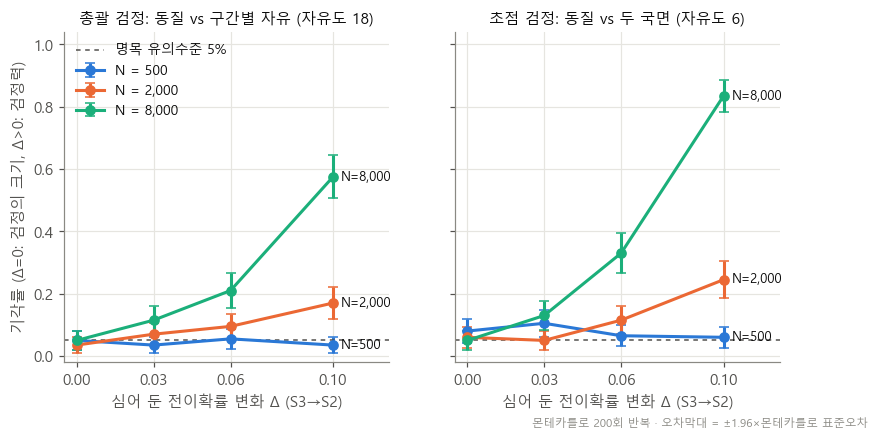

In [11]:
if not (OUT / 'mc_summary.csv').exists():
    import subprocess
    subprocess.run([sys.executable, str(HERE / '03_monte_carlo.py')], check=True)
mc = pd.read_csv(OUT / 'mc_summary.csv'); mck = pd.read_csv(OUT / 'mc_kselect_summary.csv')
display(mc.round(4)); display(mck.round(2))

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.9), sharey=True)
for ax, col, se, title in [(axes[0], 'reject_rate', 'reject_mcse', '총괄 검정: 동질 vs 구간별 자유 (자유도 18)'),
                           (axes[1], 'reject_rate_regime', 'reject_mcse_regime', '초점 검정: 동질 vs 두 국면 (자유도 6)')]:
    for i, n_ in enumerate(sorted(mc['N'].unique())):
        g = mc[mc['N'] == n_].sort_values('delta')
        ax.errorbar(g['delta'], g[col], yerr=1.96 * g[se], color=C[i], lw=2, marker='o', ms=6, capsize=3, label=f'N = {n_:,}')
        ax.text(g['delta'].iloc[-1] + 0.003, g[col].iloc[-1], f'N={n_:,}', va='center', fontsize=8.5)
    ax.axhline(0.05, color=INK2, lw=1, ls=(0, (3, 3)), label='명목 유의수준 5%')
    ax.set_title(title, fontsize=10); ax.set_xticks(sorted(mc['delta'].unique())); ax.set_xlim(-0.005, 0.122)
    ax.set_xlabel('심어 둔 전이확률 변화 Δ (S3→S2)'); ax.set_ylim(-0.02, 1.04)
axes[0].set_ylabel('기각률 (Δ=0: 검정의 크기, Δ>0: 검정력)'); axes[0].legend(loc='upper left', fontsize=9)
savefig(fig, 'fig08_monte_carlo_power', '몬테카를로 200회 반복 · 오차막대 = ±1.96×몬테카를로 표준오차')

## D. 구현 교차검증 (선택)
`02_RUN_ALL.R` 을 실행하면 R 로 다시 구현한 EM 과 (설치되어 있으면) **LMest** 패키지가 같은 자료·같은 사양으로 적합한 결과를
`outputs/r_crosscheck.csv` 에 남긴다. 아래 셀은 그 파일이 있을 때 파이썬 결과와 비교한다.

In [12]:
py = dict(loglik_het=best['loglik'], npar_het=best['npar'], bic_het=best['bic'], loglik_hom=hom['loglik'], loglik_regime=reg['loglik'],
          loglik_free_theta=free['loglik'], K=K_SEL)
json.dump({**py, 'pi': best['pi'].tolist(), 'A': best['A'].tolist(), 'theta': best['theta'][0].tolist()},
          open(OUT / 'python_estimates.json', 'w'), indent=1)
rc = OUT / 'r_crosscheck.csv'
if rc.exists():
    r = pd.read_csv(rc)
    r['python'] = r['quantity'].map(py)
    r['abs_diff'] = (r['value'] - r['python']).abs()
    display(r)
else:
    print('outputs/r_crosscheck.csv 없음 → 02_RUN_ALL.R 을 실행하면 비교표가 만들어집니다.')

,quantity,source,value,python,abs_diff
0,loglik_het,R_EM,-70404.048231,-70404.048201,2.959772e-05
1,npar_het,R_EM,38.000000,38.000000,0.000000e+00
2,bic_het,R_EM,141159.220008,141159.219949,5.919565e-05
3,loglik_hom,R_EM,-70417.554844,-70417.554844,1.227163e-07
4,loglik_regime,R_EM,-70412.014941,-70412.014941,4.091271e-07
5,loglik_free_theta,R_EM,-70384.812617,-70384.812542,7.590292e-05
6,K,R_EM,3.000000,3.000000,0.000000e+00
7,loglik_het,LMest,-70404.047958,-70404.048201,2.426802e-04
8,npar_het,LMest,38.000000,38.000000,0.000000e+00
9,bic_het,LMest,141159.219463,141159.219949,4.853604e-04


In [13]:
json.dump(dict(data_mode=DATA_MODE, n_persons=int(N), n_waves=int(T), n_items=int(J), person_waves=int(obs_wave.sum()),
               n_complete=int((obs_wave.sum(1) == T).sum()), n_patterns=int(best['n_patterns']), K_selected=K_SEL,
               n_starts=N_STARTS, n_boot=N_BOOT, n_boot_valid=len(valid),
               coverage=None if A_TRUE is None else dict(theta=[int(prof['covered'].sum()), len(prof)], A=[int(trans['covered'].sum()), len(trans)],
                                                         occ=[int(occ['covered'].sum()), len(occ)]),
               max_abs_err=None if A_TRUE is None else dict(theta=float((prof['estimate'] - prof['true']).abs().max()),
                                                            A=float((trans['estimate'] - trans['true']).abs().max()))),
          open(OUT / 'run_summary.json', 'w', encoding='utf-8'), indent=1)
print('저장된 표:')
for p in sorted(OUT.glob('*')):
    if p.suffix in ('.csv', '.json'):
        print('  outputs/' + p.name)
print('저장된 그림:')
for p in sorted(FIG.glob('fig*.png')):
    print('  figures/' + p.name)

저장된 표:
  outputs/bivariate_residuals.csv
  outputs/calibration_check.csv
  outputs/classification_diagnostics.json
  outputs/cov_coefficients.csv
  outputs/cov_interaction_tests.csv
  outputs/cov_mc_replicates.csv
  outputs/cov_mc_summary.csv
  outputs/cov_model_comparison.csv
  outputs/cov_predicted_transitions.csv
  outputs/cov_summary.json
  outputs/fact_check.csv
  outputs/mc_kselect_replicates.csv
  outputs/mc_kselect_summary.csv
  outputs/mc_replicates.csv
  outputs/mc_summary.csv
  outputs/measurement_invariance.csv
  outputs/model_selection.csv
  outputs/observed_prevalence_by_wave.csv
  outputs/paper_audit.csv
  outputs/paper_numbers.json
  outputs/prop1_crosstab.csv
  outputs/prop1_service_types.csv
  outputs/prop1_summary.json
  outputs/python_estimates.json
  outputs/r_crosscheck.csv
  outputs/r_model_selection.csv
  outputs/r_response_profiles.csv
  outputs/r_transition_probabilities.csv
  outputs/real_cov_coefficients.csv
  outputs/real_exposure_logit.csv
  outputs/real_h